# Understanding the depth correction

The float listens at its park depth, about 1000 m, but the wind makes its
noise at the surface.  On the way down, the sound spreads and is absorbed,
so the level at the hydrophone is lower than just below the surface.  The
**depth correction β** (dB) is that difference:

> level just below the surface ≈ level at the hydrophone + β

β depends on depth, on frequency (absorption grows with frequency), and on
the sound-speed profile, which bends the sound paths.  ArgoPAL computes it
from the float's own temperature and salinity profiles, with the ray
method of Vagle et al. (1990) as implemented by Cauchy et al. (2018).

This notebook shows what β is and how much each choice changes it, and
the wind, on float **7902280**:

1. one profile: sound speed and β with depth
2. frequency and absorption
3. β through the seasons
4. one β per profile, or one for the deployment
5. data mode: delayed or raw profiles
6. measurements without β
7. the effect on wind speed
8. how absorption is applied

In [1]:
import warnings

import gsw
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import argopal

warnings.simplefilter("ignore")

BANDS = (1000, 8000, 20000)
r = argopal.process_float(7902280, mode="raw", bands=BANDS, verbose=False)
ts, beta, park = r["ts_profiles"], r["beta"], r["park"]

## 1. One profile: sound speed and β with depth

A winter and a summer profile.  Sound speed (TEOS-10) follows temperature
near the surface and pressure at depth; in summer the warm surface layer
makes it much faster near the surface.

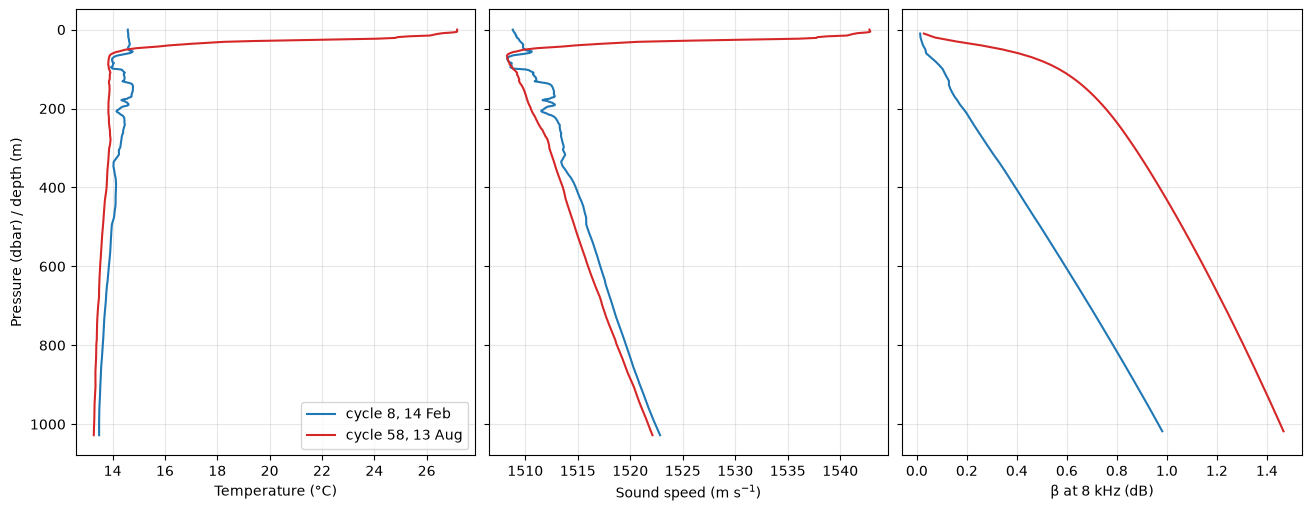

In [2]:
def profile_near(date):
    t = ts.groupby("cycle")["datetime"].first()
    return int((t - pd.Timestamp(date)).abs().idxmin())


winter, summer = profile_near("2026-02-15"), profile_near("2026-08-15")


def sound_speed(p):
    sa = gsw.SA_from_SP(p["salinity"], p["pressure"], p["longitude"], p["latitude"])
    ct = gsw.CT_from_t(sa, p["temperature"], p["pressure"])
    return gsw.sound_speed(sa, ct, p["pressure"])


fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 5), sharey=True,
                                    layout="constrained")
for cycle, colour in ((winter, "tab:blue"), (summer, "tab:red")):
    p = ts[ts["cycle"] == cycle]
    label = f"cycle {cycle}, {p['datetime'].iloc[0]:%d %b}"
    ax1.plot(p["temperature"], p["pressure"], color=colour, label=label)
    ax2.plot(sound_speed(p), p["pressure"], color=colour)
    b = beta[beta["cycle"] == cycle]
    ax3.plot(b["beta_8000Hz"], b["depth"], color=colour)
ax1.set_xlabel("Temperature (°C)")
ax2.set_xlabel("Sound speed (m s$^{-1}$)")
ax3.set_xlabel("β at 8 kHz (dB)")
ax1.set_ylabel("Pressure (dbar) / depth (m)")
ax1.invert_yaxis()
ax1.legend()
for ax in (ax1, ax2, ax3):
    ax.grid(alpha=0.3)

β grows with depth: the deeper the hydrophone, the more the surface sound
has spread and been absorbed.  At the park depth the summer profile gives
about half a dB more: its warm surface layer bends the sound paths.

## 2. Frequency and absorption

Absorption (Francois & Garrison 1982) grows steeply with frequency, so β
does too:

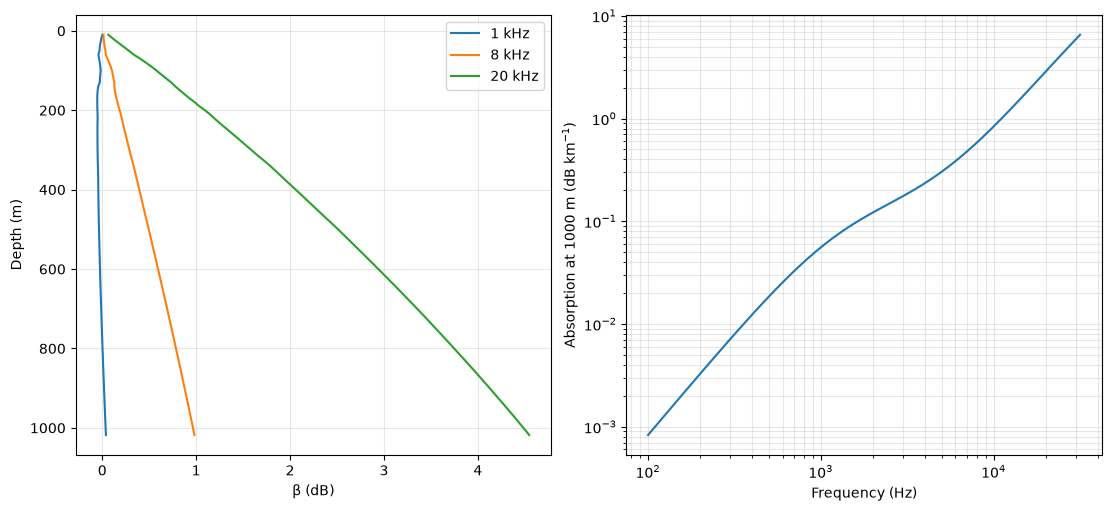

In [3]:
b = beta[beta["cycle"] == winter]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for f in BANDS:
    ax1.plot(b[f"beta_{f}Hz"], b["depth"], label=f"{f / 1000:g} kHz")
ax1.invert_yaxis()
ax1.set_xlabel("β (dB)")
ax1.set_ylabel("Depth (m)")
ax1.legend()

p = ts[(ts["cycle"] == winter) & (ts["pressure"] == 1000)].iloc[0]
freqs = np.logspace(2, 4.5, 50)
alpha = np.array([
    argopal.absorption_francois_garrison(
        f / 1000, np.array([1000.0]), np.array([p["temperature"]]),
        np.array([p["salinity"]]),
    )[0]
    for f in freqs
])
ax2.loglog(freqs, alpha * 1000)
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Absorption at 1000 m (dB km$^{-1}$)")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3, which="both")

In [4]:
at_park = b.loc[(b["depth"] - 1000).abs().idxmin()]
print(f"β at {at_park['depth']:.0f} m, cycle {winter}:",
      {f"{f / 1000:g} kHz": round(float(at_park[f"beta_{f}Hz"]), 2) for f in BANDS})

β at 1000 m, cycle 8: {'1 kHz': 0.04, '8 kHz': 0.97, '20 kHz': 4.48}


## 3. β through the seasons

β at 1000 m for every profile: it follows the seasonal change of the
sound-speed profile.

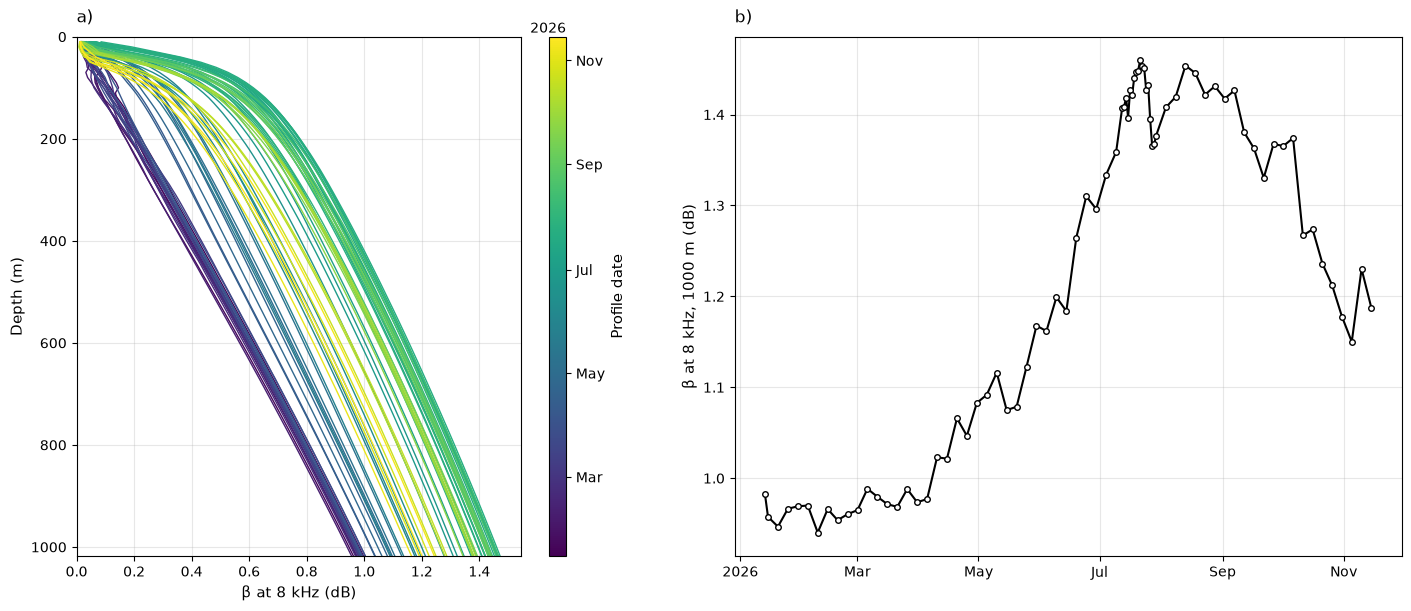

In [5]:
fig, axes = argopal.plot_beta(beta, band=8000)

## 4. One β per profile, or one for the deployment

By default ArgoPAL computes β from **every** profile and interpolates it
in time between the profiles before and after each measurement
(`beta_method="interpolate"`).  `beta_method="mean"` uses one β from the
deployment-mean profile instead, as in Delaigue et al. (2026).

difference: -0.30 to 0.22 dB


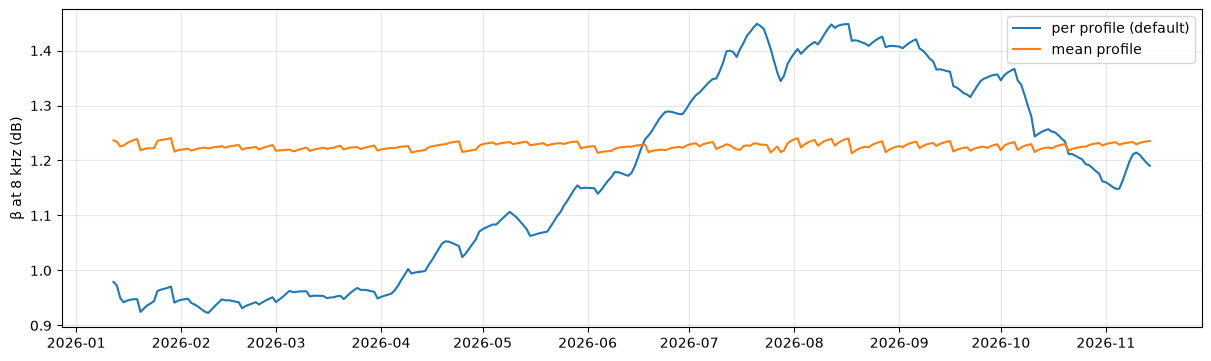

In [6]:
r_mean = argopal.process_float(
    7902280, mode="raw", bands=BANDS, beta_method="mean", verbose=False
)
both = pd.DataFrame({
    "datetime": park["datetime"],
    "per_profile": park["beta_8000Hz"],
    "mean_profile": r_mean["park"]["beta_8000Hz"],
}).set_index("datetime").resample("1D").mean()

fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
ax.plot(both.index, both["per_profile"], label="per profile (default)")
ax.plot(both.index, both["mean_profile"], label="mean profile")
ax.set_ylabel("β at 8 kHz (dB)")
ax.grid(alpha=0.3)
ax.legend()
diff = both["per_profile"] - both["mean_profile"]
print(f"difference: {diff.min():.2f} to {diff.max():.2f} dB")

## 5. Data mode: delayed or raw profiles

The profiles used for β come from the chosen data mode only.  In delayed
mode (the default), only quality-controlled profiles are used; for a
recent float most of them are not in delayed mode yet, so β, and the wind,
stop where the delayed-mode profiles stop:

measurements with β: {'raw': 1.0, 'delayed': 0.63}
where both exist, delayed − raw: 0.059 dB at most


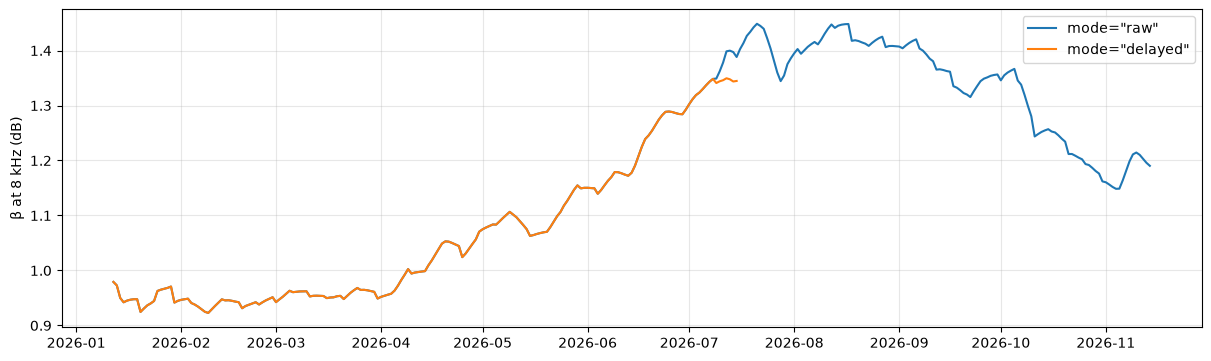

In [7]:
r_delayed = argopal.process_float(7902280, bands=BANDS, verbose=False)
modes = pd.DataFrame({
    "datetime": park["datetime"],
    "raw": park["beta_8000Hz"],
    "delayed": r_delayed["park"]["beta_8000Hz"],
}).set_index("datetime")

fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
for col in ("raw", "delayed"):
    d = modes[col].resample("1D").mean()
    ax.plot(d.index, d, label=f'mode="{col}"')
ax.set_ylabel("β at 8 kHz (dB)")
ax.grid(alpha=0.3)
ax.legend()
print("measurements with β:", modes.notna().mean().round(2).to_dict())
both_modes = modes.dropna()
print(f"where both exist, delayed − raw: "
      f"{(both_modes['delayed'] - both_modes['raw']).abs().max():.3f} dB at most")

## 6. Measurements without β

β is only interpolated between profiles; more than 6 days before the
first or after the last usable profile it is left empty rather than
borrowed from another season (`depth_correct(..., max_extrapolation="6D")`).
In raw mode this float has profiles all along, so every measurement has a
β; in delayed mode, β stops 6 days after the last delayed-mode profile.
The grey period below has no β:

mode="raw": 0% of measurements without β
mode="delayed": 37% of measurements without β


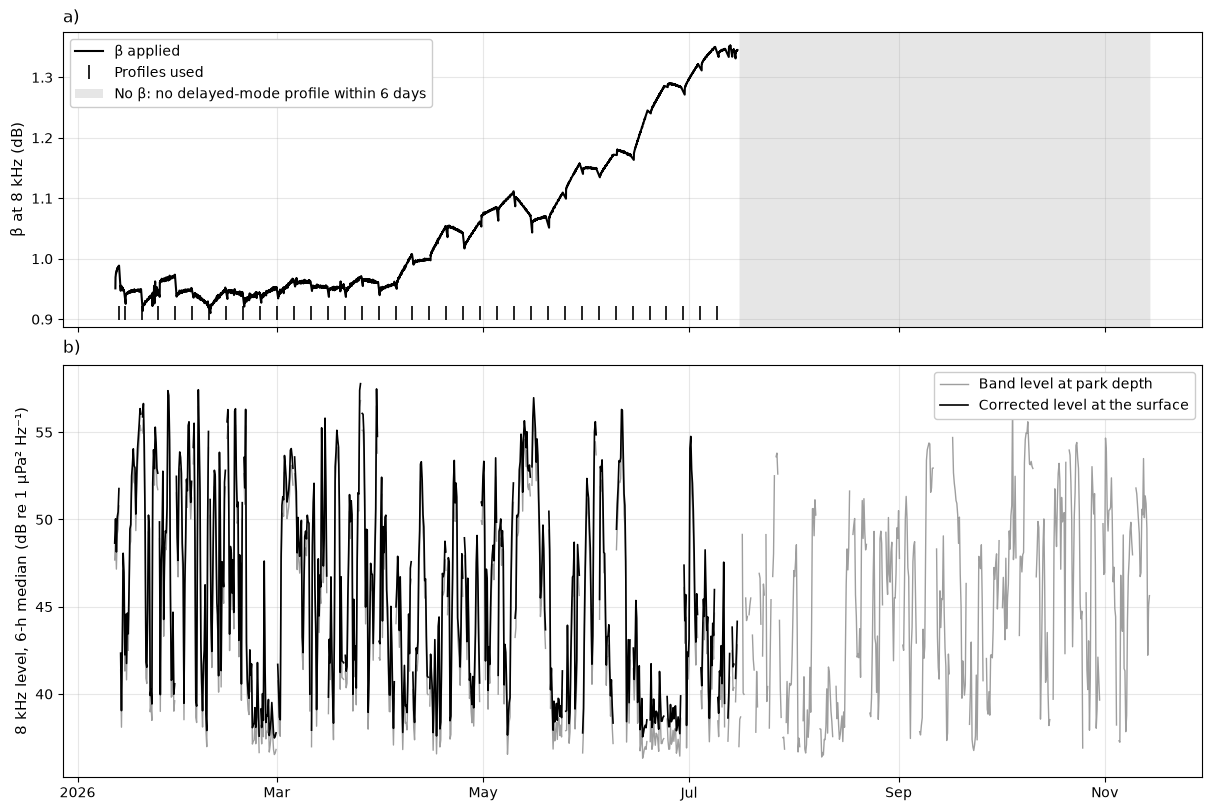

In [8]:
for name, res in (("raw", r), ("delayed", r_delayed)):
    missing = res["park"]["beta_8000Hz"].isna().mean()
    print(f'mode="{name}": {missing:.0%} of measurements without β')
fig, axes = argopal.plot_depth_correction(
    r_delayed["park"], band=8000, beta=r_delayed["beta"]
)

## 7. The effect on wind speed

This float divides its band levels by the bandwidth on board, so the band
level is already a spectral level, only not depth-corrected.  The
published Nystuen et al. (2015) wind with and without β:

β at 8 kHz: 1.16 dB on average
wind with β minus without: 0.95 m/s on average, 0.32 to 1.81 (5–95%)


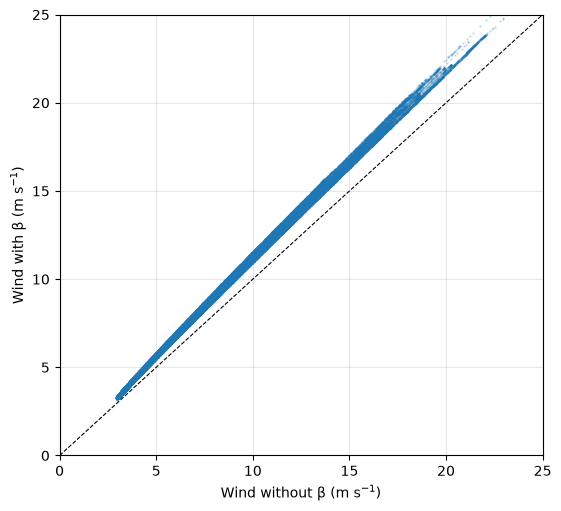

In [9]:
u_with = park["U_nystuen2015"]
u_without = argopal.wind_nystuen2015(park["f_8000Hz"])
d = (u_with - u_without).dropna()
print(f"β at 8 kHz: {park['beta_8000Hz'].mean():.2f} dB on average")
print(f"wind with β minus without: {d.mean():.2f} m/s on average, "
      f"{d.quantile(0.05):.2f} to {d.quantile(0.95):.2f} (5–95%)")

fig, ax = plt.subplots(figsize=(5.5, 5), layout="constrained")
ax.plot(u_without, u_with, ".", ms=1, alpha=0.3)
ax.plot([0, 25], [0, 25], "k--", lw=0.8)
ax.set_xlabel("Wind without β (m s$^{-1}$)")
ax.set_ylabel("Wind with β (m s$^{-1}$)")
ax.set_xlim(0, 25)
ax.set_ylim(0, 25)
ax.grid(alpha=0.3)

The correction matters more for strong winds, where the models are
steeper.  When the models are refitted to a reference wind, part of a
constant offset is absorbed by the fitted coefficients, but the seasonal
change of β is not.

## 8. How absorption is applied

The Francois & Garrison coefficient α is in dB per metre, so the power
left after a path of length L is 10^(−αL/10).  The original MATLAB code
used exp(−αL), as if α were in nepers per metre, which overestimates
absorption about 4.3 times.  ArgoPAL applies it in dB; the original
convention is kept for comparison (`absorption_units="Np"`):

In [10]:
p = ts[ts["cycle"] == winter]
p = p[(p["pressure"] >= 1) & (p["pressure"] <= 1000)]
depth = -gsw.z_from_p(p["pressure"].to_numpy(), p["latitude"].iloc[0])
grid = np.arange(1, int(depth.max()) + 1, dtype=float)
on_grid = {
    v: np.interp(grid, depth, p[v].to_numpy())
    for v in ("temperature", "salinity", "pressure")
}
sa = gsw.SA_from_SP(on_grid["salinity"], on_grid["pressure"],
                    p["longitude"].iloc[0], p["latitude"].iloc[0])
ct = gsw.CT_from_t(sa, on_grid["temperature"], on_grid["pressure"])
c = gsw.sound_speed(sa, ct, on_grid["pressure"])

rows = {}
for units in ("dB", "Np"):
    b = argopal.beta_profile(
        grid, c, on_grid["temperature"], on_grid["salinity"], [8000],
        receiver_depths=np.array([500.0, grid[-1]]), absorption_units=units,
    )
    rows[units] = b.set_index("depth")["beta_8000Hz"].round(2)
pd.DataFrame(rows).rename(columns={"dB": "in dB (ArgoPAL)",
                                   "Np": "as exp(−αL) (original code)"})

,in dB (ArgoPAL),as exp(−αL) (original code)
depth,,
500.0,0.50,2.22
989.0,0.96,3.98


At the park depth and 8 kHz, β is about 1 dB, not 4 dB: with the original
convention the levels, and the winds, would be overestimated.

**Summary.**  β is about 1 dB at 8 kHz and 1000 m, larger at higher
frequency and depth, and changes with the seasons (here from 0.9 dB in
winter to 1.45 dB in summer, about 0.5 m s⁻¹ of wind).  Computing it per profile follows that change; the data mode
decides which profiles exist; and near the start and end of the record
some measurements have no β.